This is a tutorial for the ThreeBodyTB.jl code, using the python inteface tb3py (see github.com/usnistgov/tb3py). This first code block just downloads and installs the python interface, which is very fast.

In [1]:
!git clone https://github.com/usnistgov/tb3py
%cd tb3py
!pip install -e .
!export JULIA_NUM_THREADS=1
!export PYTHON_JULIACALL_HANDLE_SIGNALS=yes

Cloning into 'tb3py'...
remote: Enumerating objects: 597, done.
remote: Counting objects: 100% (597/597), done.
remote: Compressing objects: 100% (326/326), done.
remote: Total 597 (delta 235), reused 593 (delta 231), pack-reused 0 (from 0)
Receiving objects: 100% (597/597), 891.70 KiB | 9.19 MiB/s, done.
Resolving deltas: 100% (235/235), done.
/content/tb3py
Obtaining file:///content/tb3py
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for tb3py (pyproject.toml) ... done
  Created wheel for tb3py: filename=tb3py-0.1.0-0.editable-py3-none-any.whl size=5942 sha256=8488d310d7b9558b58c6cce0bece828a0601b192ed9a46d99b98b2a136016a36
  Stored in directory: /tmp/pip-ephem-wheel-cache-2d62tp0d/wheels/fa/3a/3a/d4dec1c0364f99b29a9fa8beff1f37ad1a529d7a232a7a927a
Successfully built tb3py
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

**Setup code.** Unfortunately, the import statement below takes about 25 minutes to run. I recommend you install the code locally if you plan to use it more than once. The reason it is slow is that it is doing a lot of ahead of time compilation that won't happen the second time you import it. However, that obviously doesn't work well with Colab notebooks, where you lose everything if you disconnect.

In [20]:
import tb3py as tb3


**Silicon example**, loading structure from a VASP POSCAR-formatted file.

In [21]:
c = tb3.jl.makecrys("POSCAR_example")


found /root/.julia/packages/ThreeBodyTB/s358m/src/../dats/pbesol/v1.3/els/coef.el.2bdy.Si.xml.gz
Tuple{Symbol, Symbol}
found /root/.julia/packages/ThreeBodyTB/s358m/src/../dats/pbesol/v1.3/els/coef.el.3bdy.Si.xml.gz


START SCF ----------------
SCF CALC 0001 energy  -10.87781751    
SCF CALC 0002 energy  -10.87781751  en_diff:   2.416857E-14  dq_diff:   4.440892E-15   mix: 4.000000E-01 

YES convergence in 2 iters, energy -10.877817514264262 eV  
END SCF ------------------

ΔQ = [0.0, 0.0]

scf_energy success, done

Formation energy: 0.106 eV/atom

Symmetry info
Space group # 227     Fd-3m      F 4d 2 3 -1d
Point group   m-3m
spg 227 Fd-3m F
6.948 6.948 6.948  |  60.0 60.0 60.0
centering F true
need to rerun in standard structure for symmetry

START SCF ----------------
SCF CALC 0001 energy  -10.87781751    
SCF CALC 0002 energy  -10.87781751  en_diff:   0.000000E+00  dq_diff:   7.105427E-15   mix: 4.000000E-01 

YES convergence in 2 iters, energy -10.877817514264287 eV  
END SCF ----

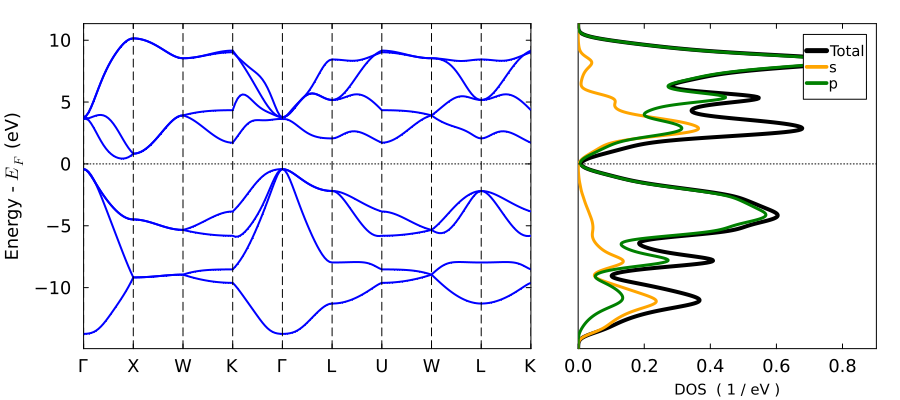

(Julia:
 
 tb_crys object (DENSE)
 
 Units: Å
 
 A1=     0.00000  2.60000  2.60000
 A2=     2.60000  0.00000  2.60000
 A3=     2.60000  2.60000  0.00000
 
 Si   0.00000  0.00000  0.00000
 Si   0.25000  0.25000  0.25000
 
 
 nelec: 8.0; nspin (hoppings): 1
 within_fit: true  ; scf: true; scfspin: false
 calculated energy: -10.878 eV
 formation energy: 0.106 eV
 efermi  : -2.473 eV
 charges : [-0.0, -0.0]
 
 
 tight binding real space object (DENSE); nwan = 8, nr = 69, nonorth = true, scf = true, scfmagnetic = false, nspin = 1
 
 
 ,
 Julia: Plot{Plots.GRBackend() n=23})

GKS: cannot open display - headless operation mode active


In [5]:
en, tbc, flag = tb3.jl.scf_energy(c)
tb3.jl.plot_bandstr_dos(tbc)

**Graphene example.** Creating structure from numpy arrays.

Symmetry info
Space group # 191     P6/mmm      -P 6 2
Point group   6/mmm
spg 191 P6/mmm P
4.878 4.878 100.0  |  90.0 90.0 120.0

START SCF ----------------
SCF CALC 0001 energy  -18.77302972    
SCF CALC 0002 energy  -18.77302972  en_diff:   0.000000E+00  dq_diff:   1.660894E-12   mix: 5.000000E-02 

YES convergence in 2 iters, energy -18.773029723349868 eV  
END SCF ------------------

ΔQ = [0.0, 0.0]

align fermi -0.21318282819080778 -------------------------
no display
proj_type missing
grid [22, 22, 3]
dos fermi -0.21287132228035655 xxxxxxxxxxxxx---------------
nspin 1
Projection type: orbs
proj_inds [1, 5]
proj_inds [2, 3, 4, 6, 7, 8]
(1452, 8, 2, 1)
Int DOS 7.9999998690009475
Int DOS occ 3.999923835631123
Int pDOS occ 1 : 0.9694446065364452
Int pDOS occ 2 : 3.0304792290946767
Int pDOS all 1 : 1.9999999998351146
Int pDOS all 2 : 5.999999869165831
DOS flit range (-20.31528646115864, 15.220983043378983)


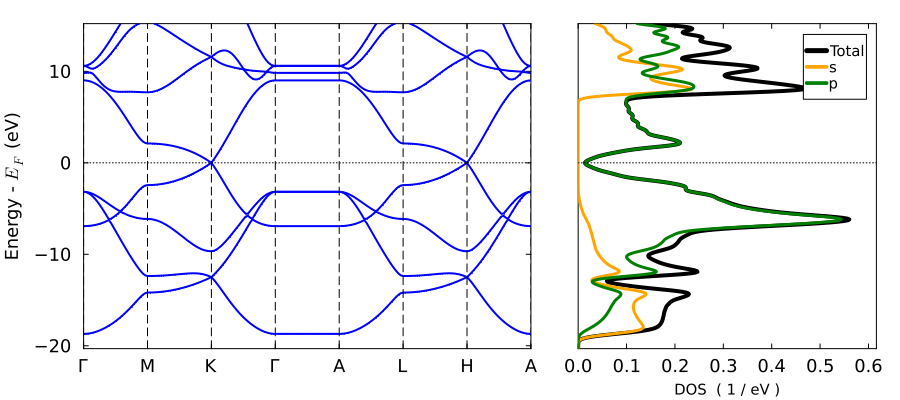

In [18]:
import numpy as np
coords = np.array([[0.0, 0.0, 0.0], [0.6666666666666667, 0.3333333333333333, 0.0]])
A = np.array(  [[4.8778320899957182e+00, 0.0, 0.0], [ -2.4389160449978591e+00 ,  4.2243265053312333e+00,   0.0],[ 0.0, 0.0, 100.0]]) * 0.529177
atoms = ["C", "C"]
c_graphene = tb3.jl.makecrys(A, coords, atoms)
ret = tb3.jl.plot_bandstr_dos(c_graphene)

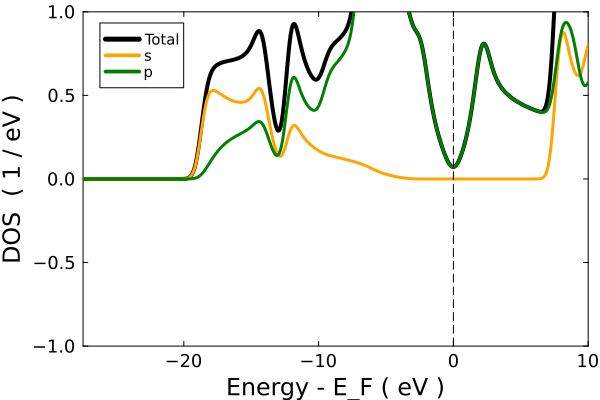

Supercell




START SCF ----------------
SCF CALC 0001 energy  -75.09417712    
SCF CALC 0002 energy  -75.09417712  en_diff:   9.667430E-14  dq_diff:   5.835332E-12   mix: 5.000000E-02 

YES convergence in 2 iters, energy -75.09417711561679 eV  
END SCF ------------------

ΔQ = [-0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0, -0.0]

scf_energy success, done

Formation energy: 0.055 eV/atom

proj_type missing
grid [13, 13, 3]
dos fermi -0.2128664575749934 xxxxxxxxxxxxx---------------
nspin 1
Projection type: orbs
proj_inds [1, 5, 9, 13, 17, 21, 25, 29]
proj_inds [2, 3, 4, 6, 7, 8, 10, 11, 12, 14, 15, 16, 18, 19, 20, 22, 23, 24, 26, 27, 28, 30, 31, 32]
(507, 32, 2, 1)
Int DOS 31.999986254249958
Int DOS occ 15.999926703127977
Int pDOS occ 1 : 3.877778426150031
Int pDOS occ 2 : 12.122148276977947
Int pDOS all 1 : 7.9999999767996455
Int pDOS all 2 : 23.99998627745031


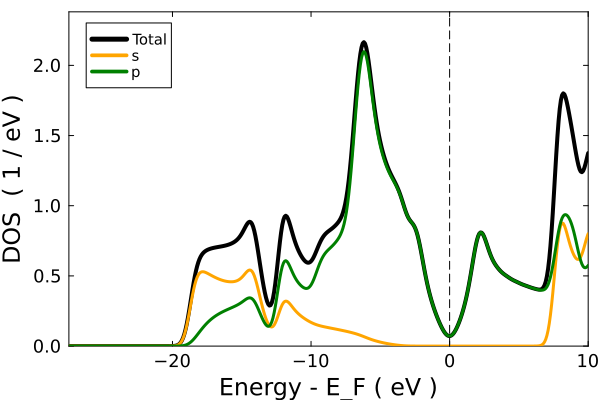

In [33]:
c221 = tb3.jl.ThreeBodyTB.CrystalMod.generate_supercell(c_graphene, [2,2,1])
en, tbc, flag = tb3.jl.scf_energy(c221)
tb3.jl.dos(tbc);

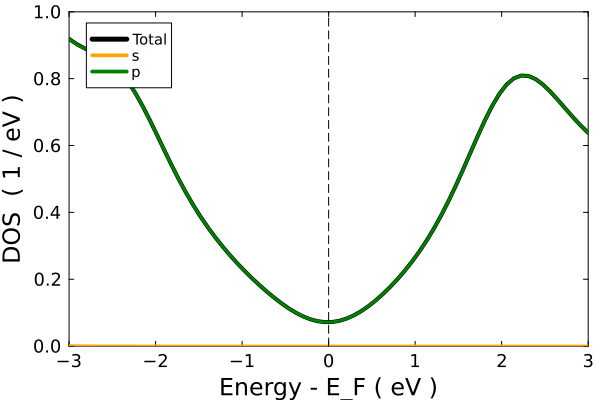

In [38]:
tb3.jl.ylims_b(0.0, 1.0)
tb3.jl.xlims_b(-3, 3)